# Práctica 3. Black-Litterman y paridad de riesgo jerárquica

Markowitz produce carteras inestables y concentradas, por eso el objetivo de esta práctica es explorar las alternativas propuestas en los modelos de **Black-Litterman** y **HRP**. A lo largo de este notebook vamos a recorrer los diferentes pasos que hemos realizado para implementar estas técnicas incluyendo las diferentes decisiones que hemos tomado en referencia al universo de activos, mandato de inversión y cartera de mercado.


In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## 0. Mandato

El primer paso de la práctica era decidir un mandato y un universo de activos. Para hacerlo de la forma más profesional y realista posible, hemos investigado por nuestra cuenta los diferentes formatos y hemos decidido utilizar el IPS (Investment Policy Statement) tal y como lo estructura el CFA Institute.

| | Elemento | Mandato |
|---|---|---|
| **Objetivos** | Rentabilidad | Crecimiento del capital a largo plazo; batir al benchmark en ~2-3 % anual |
| | Riesgo | Volatilidad objetivo de ~8-10 % anual, en línea con el benchmark; caída máxima tolerable de ~30 % |
| **Restricciones** | Horizonte | 10 años |
| | Impuestos | No se consideran (simplificación académica) |
| | Liquidez | Sin necesidades de liquidez a corto plazo |
| | Legal | Solo ETF cotizados y líquidos; solo largos; sin derivados ni apalancamiento |
| | Circunstancias particulares | Ninguna |
| **Política** | Moneda base | USD |
| | Clases de activo | Renta variable y renta fija |
| | Benchmark | Cartera de mercado de nuestro universo: los 11 ETF con los pesos w_mkt fijos (Doeswijk, cierre de 2012; apartado 2), rebalanceada trimestralmente |
| | Rebalanceo | Trimestral |

Para el universo de activos hemos elegido dos clases, renta variable y renta fija. Dentro de cada una buscábamos un conjunto de ETF que representara más o menos el mercado mundial. El problema es que Black-Litterman necesita además los pesos de ese mercado, y conseguir unos pesos realistas ha sido bastante más difícil de lo que parecía. Al final la elección del universo y la de los pesos han ido de la mano.

Lo primero que probamos fue usar los activos bajo gestión de los ETF. Es el dato más fácil de conseguir, pero mide cuánto dinero ha entrado en cada fondo además de cuánto se han revalorizado sus activos y no cuánto vale cada mercado. Los ETF son un vehículo muy habitual para invertir en acciones y mucho menos para invertir en bonos, así que la renta fija salía infraponderada. El sesgo también aparecía dentro de cada clase. Con los activos de hoy, SPY e IWM suman el 89 % de la renta variable del universo, cuando EE. UU. pesa en torno al 64 % del MSCI ACWI. BWX no llega al 2 % de la deuda pública del universo, y la deuda pública de fuera de EE. UU. es más de la mitad del total mundial. Los ETF que cotizan en EE. UU. los compran sobre todo inversores estadounidenses, y algunos, como SPY, TLT o HYG, se usan mucho para operar a corto plazo.

La alternativa era la capitalización de mercado de los índices replicados en el caso de la renta variable o el valor de mercado en el caso de los instrumentos de renta fija. La mayoría de estos datos son de difícil acceso o de pago, por lo que no eran una opción a la hora de sacar los pesos de la cartera de mercado. Finalmente hemos decidido usar como referencia la cartera de mercado global multiactivo de Doeswijk, Lam y Swinkels, publicada en el Financial Analysts Journal (2014) con el título «The Global Multi-Asset Market Portfolio, 1959–2012». Los autores estiman el valor de mercado de cada clase de activo a escala mundial a partir de los principales índices de referencia, y mantienen una actualización anual de los datos hasta 2023 (Doeswijk, Lam y Swinkels, 2024). 


Quedaba decidir si los pesos debían cambiar con el tiempo. Probamos a actualizarlos con los precios a partir de 2012, y en 2023 la renta variable salía con un 64 % cuando en el paper es un 49 %. Los precios no recogen la deuda nueva que emiten los gobiernos cada año, y el error crece unos 1,3 puntos por año. Actualizar con cada foto anual del paper sí funcionaba, pero a partir de 2023 no hay más datos. Al mirar la serie vimos además que el reparto entre clases cambia poco. Desde 2013 la renta variable se mueve entre el 43 % y el 49 % del total.

Por eso usamos una foto fija, la de cierre de 2012. Es la última anterior al inicio del backtest fuera de muestra, a mediados de 2013, así que no usa información posterior. El paper se publicó en 2014, pero los datos son los de cierre de 2012. Los pesos no cambian, pero las rentabilidades de equilibrio sí, porque la matriz de covarianzas se vuelve a estimar en cada rebalanceo. Para que los pesos del paper encajen con nuestros activos sin inventar repartos, elegimos los ETF de forma que cada uno corresponda a una fila de la cartera de Doeswijk. Esto tiene un coste. El universo es menos detallado de lo que nos habría gustado, y algunos ETF solo cubren la parte estadounidense de su fila. A cambio, la cartera de mercado es coherente, se puede comprobar con los datos del paper y depende de muy pocos supuestos externos.

La moneda base es el dólar. Todos los ETF del universo cotizan en dólares y los datos de la cartera de mercado de Doeswijk también están en dólares, así que no hace falta convertir nada. Con el euro como moneda base, la rentabilidad de toda la cartera dependería además del tipo de cambio, y ese es un riesgo que el mandato no busca.

Pedimos batir al benchmark en un 2-3 % anual. Para una gestión activa es un objetivo moderado. La cartera es solo larga y sin apalancamiento por simplificar la práctica.

El riesgo lo fijamos a partir del benchmark. Entre 2010 y 2026, la cartera de mercado ha tenido una volatilidad del 8,5 % anual y una caída máxima del 25 %, en 2022, cuando cayeron a la vez la bolsa y los bonos. Pedimos una volatilidad parecida, del 8-10 %, y aceptamos caídas de hasta un 30 %.

## 1. Universo

Once ETF en dos clases de activo, con historia común desde julio de 2010. La fecha la marca EMLC, que es el que empieza a cotizar más tarde.

| Clase | Fila de Doeswijk | Ticker | Qué es | Desde |
|---|---|---|---|---|
| Renta variable | MSCI ACWI: EE. UU. | SPY | S&P 500 | 1993 |
| | MSCI ACWI: desarrollados ex-EE. UU. | EFA | MSCI EAFE (Europa, Australasia y Lejano Oriente) | 2001 |
| | MSCI ACWI: emergentes | EEM | MSCI Emerging Markets | 2003 |
| Renta fija | Deuda pública: EE. UU. | IEF | Tesoro 7-10 años | 2002 |
| | Deuda pública: EE. UU. | TLT | Tesoro 20+ años | 2002 |
| | Deuda pública: ex-EE. UU. | BWX | Soberanos ex-EE. UU. en moneda local, sin cubrir | 2007 |
| | Crédito investment grade | LQD | Corporativa IG de EE. UU. | 2002 |
| | High yield | HYG | High yield de EE. UU. | 2007 |
| | Ligados a inflación | TIP | TIPS de EE. UU. | 2003 |
| | Deuda emergente: soberana en USD | EMB | J.P. Morgan EMBI Global Core | 2007 |
| | Deuda emergente: soberana en moneda local | EMLC | J.P. Morgan GBI-EM Global Core | 2010 |

El universo sale de la cartera de mercado global de Doeswijk, Lam y Swinkels (2014). Cada ETF representa una fila de esa cartera, de modo que su peso de mercado se obtiene casi directamente de sus datos. Solo hacen falta tres números de fuera para repartir las filas que tienen más de un ETF.

Antes de tomar esta decisión probamos un universo de 16 ETF, con las regiones de renta variable por separado (VGK, EWJ, EWC y EPP), las small caps de EE. UU. y del resto del mundo (IWM y SCZ) y la deuda hipotecaria (MBB). Era más rico y detallado, pero para estimar los pesos de mercado hacían falta unos varios supuestos que nos parecían imprecisos. Nuestro criterio ha sido escoger un universo algo más grueso a cambio de que la cartera de mercado sea coherente y fácil de estimar. De este modo, nos quedamos solo con renta variable y renta fija, que en 2012 suman el 91 % de la cartera de Doeswijk. 

La renta variable va en tres bloques, EE. UU. (SPY), desarrollados fuera de EE. UU. (EFA) y emergentes (EEM). Es el reparto natural del MSCI ACWI, y para separarlo basta con dos números, el peso de EE. UU. y el de los emergentes en el índice. Con las regiones por separado haría falta el peso de cada una. SPY replica el S&P 500 y deja fuera las empresas medianas de EE. UU. que sí están en el ACWI. Lo aceptamos porque es el ETF más líquido del mundo y el S&P 500 se mueve casi igual que el mercado estadounidense completo. El índice de EFA no incluye Canadá. Su peso en el ACWI se suma al de EFA, que es el bloque más parecido.

En renta fija el universo sigue las filas de Doeswijk. La deuda pública se reparte entre el Tesoro de EE. UU. (IEF y TLT) y la deuda pública del resto del mundo (BWX). IEF y TLT son dos tramos del mismo emisor y se mueven de forma muy parecida. Los dejamos a propósito, porque dos activos casi redundantes son justo el caso en el que Markowitz se vuelve inestable y en el que HRP debería agruparlos. BWX no cubre la divisa. La moneda forma parte del riesgo de invertir en bonos de otros países, y la cartera de mercado medida en dólares también la lleva sin cubrir.

LQD, HYG y TIP representan filas que en Doeswijk son mundiales, el crédito investment grade, el high yield y los bonos ligados a la inflación. Los tres contienen solo bonos de EE. UU. No hemos encontrado ETF que cubran estas clases en todo el mundo con historia desde 2012, y EE. UU. es la parte más grande de cada una. La fila de crédito investment grade incluye además la deuda hipotecaria. No la separamos con MBB para no añadir otro supuesto de reparto, así que LQD representa la fila entera.

La deuda emergente entra con dos ETF, EMB para los bonos soberanos en dólares y EMLC para los soberanos en moneda local. Las dos filas existen por separado en Doeswijk y se comportan de forma distinta, porque EMLC lleva además el riesgo de las divisas emergentes. EMLC empieza a cotizar en julio de 2010 y acorta la historia común en dos años y medio. Aun así quedan más de dieciséis años de datos, suficientes para la ventana de tres años del backtest.

No incluimos ETF monetarios. El mandato no tiene necesidades de liquidez y la liquidez no forma parte de la cartera de Doeswijk. Tampoco hay ETF de factores ni de sectores. Son formas distintas de repartir las mismas acciones que ya están en SPY, EFA y EEM, y en la cartera de mercado no tienen un peso propio.

Descarga de precios y comprobación de la historia de cada activo.

In [2]:
from quantmgmt.data.prices import download_prices
from quantmgmt.risk.returns import to_returns

TICKERS = ["SPY", "EFA", "EEM", "IEF", "TLT", "BWX", "LQD", "HYG", "TIP", "EMB", "EMLC"]
INICIO, FIN = "2010-07-01", "2026-10-01"   # FIN excluido: último día = 30-sep-2026

precios = download_prices(TICKERS, start=INICIO, end=FIN)

# Primera fecha con precio de cada ETF
inicios = precios.apply(lambda s: s.first_valid_index())
print(inicios)

# Historia común: desde que cotizan todos
precios = precios.loc[inicios.max():]
print("Huecos:", precios.isna().sum().sum())

rent = to_returns(precios)
print(rent.index[0].date(), rent.index[-1].date(), rent.shape)


SPY    2010-07-01
EFA    2010-07-01
EEM    2010-07-01
IEF    2010-07-01
TLT    2010-07-01
BWX    2010-07-01
LQD    2010-07-01
HYG    2010-07-01
TIP    2010-07-01
EMB    2010-07-01
EMLC   2010-07-23
dtype: datetime64[us]
Huecos: 0
2010-07-26 2026-09-30 (4071, 11)


In [3]:
corr = rent.corr()
corr.round(2).style.background_gradient(cmap="RdBu_r", vmin=-1, vmax=1).format("{:.2f}")


,SPY,EFA,EEM,IEF,TLT,BWX,LQD,HYG,TIP,EMB,EMLC
SPY,1.00,0.85,0.77,-0.23,-0.27,0.16,0.21,0.76,-0.04,0.53,0.50
EFA,0.85,1.00,0.84,-0.20,-0.25,0.35,0.21,0.73,-0.00,0.55,0.65
EEM,0.77,0.84,1.00,-0.16,-0.21,0.31,0.19,0.66,0.01,0.54,0.67
IEF,-0.23,-0.20,-0.16,1.00,0.91,0.50,0.72,-0.00,0.79,0.33,0.12
TLT,-0.27,-0.25,-0.21,0.91,1.00,0.40,0.69,-0.08,0.73,0.28,0.04
BWX,0.16,0.35,0.31,0.50,0.40,1.00,0.49,0.32,0.46,0.47,0.57
LQD,0.21,0.21,0.19,0.72,0.69,0.49,1.00,0.43,0.67,0.62,0.39
HYG,0.76,0.73,0.66,-0.00,-0.08,0.32,0.43,1.00,0.14,0.67,0.59
TIP,-0.04,-0.00,0.01,0.79,0.73,0.46,0.67,0.14,1.00,0.45,0.23
EMB,0.53,0.55,0.54,0.33,0.28,0.47,0.62,0.67,0.45,1.00,0.67


# Parte A. Black-Litterman

Implementación en `quantmgmt/optimizers/black_litterman.py`.

## 2. Pesos de equilibrio

Definimos el mercado de nuestro universo con la foto de cierre de 2012 de la cartera de Doeswijk, Lam y Swinkels. En el apartado 0 explicamos por qué usamos el valor de mercado y no los activos bajo gestión, y por qué una foto fija en lugar de pesos que cambien con el tiempo. Ahora nos queda explicar cómo pasamos de las filas del paper a los once ETF.

Lo hacemos en dos niveles. El primero da el peso de cada clase de activo y sale entero del paper. El segundo reparte cada clase entre sus ETF cuando hay más de uno, y para eso usamos dos fuentes más, el Tesoro de EE. UU. para la deuda pública y el ETF del MSCI ACWI para la renta variable.

Doeswijk mide cada clase con el valor de mercado de un índice de referencia. Quitamos el private equity y el inmobiliario, que no están en el universo y suman un 8,7 % del total, y reescalamos el resto para que sume uno.

| Clase | Índice que usa Doeswijk | Valor en 2012 (billones de USD) | Peso reescalado | ETF |
|---|---|---|---|---|
| Renta variable | MSCI ACWI más MSCI ACWI Small Cap, sin el inmobiliario cotizado | 32,9 | 39,8 % | SPY, EFA y EEM |
| Deuda pública | Bloomberg Multiverse Government | 26,7 | 32,3 % | IEF, TLT y BWX |
| Crédito investment grade | Bloomberg Multiverse sin deuda pública ni high yield | 16,8 | 20,3 % | LQD |
| Deuda emergente | J.P. Morgan GBI-EM, EMBI Global y CEMBI Broad, y Bloomberg EM Inflation-Linked | 2,7 | 3,2 % | EMB y EMLC |
| Ligados a la inflación | Bloomberg Global Aggregate Inflation-Linked | 2,1 | 2,5 % | TIP |
| High yield | Bloomberg Global Corporate High Yield | 1,5 | 1,8 % | HYG |

Las tres últimas filas tienen un solo ETF en nuestro universo y pasan directas.

El segundo nivel, consiste en las distribuciones de pesos de la categoráis generales entre cada ETF de nuestro unvierso.

| Clase | Reparto | Dato | Fuente |
|---|---|---|---|
| Deuda pública | EE. UU. (IEF y TLT) frente al resto (BWX) | EE. UU. 32 %, resto 68 % | Notes y bonds del Tesoro a diciembre de 2012 (8,6 billones), Monthly Statement of the Public Debt, frente a los 26,7 billones de Doeswijk |
| Deuda pública de EE. UU. | IEF frente a TLT | Notes 85,5 %, bonds 14,5 % | Mismo informe del Tesoro (7,3 y 1,2 billones) |
| Renta variable | SPY, EFA y EEM | EE. UU. 45,9 %, desarrollados fuera de EE. UU. con Canadá 41,3 %, emergentes 12,8 % | Cartera por países del ETF iShares MSCI ACWI a 31 de enero de 2013, informe N-CSRS presentado a la SEC |
| Deuda emergente | EMLC frente a EMB | Moneda local 55 %, dólares 45 % | Subfilas de Doeswijk. Moneda local e inflación (0,95 y 0,53 billones) a EMLC, dólares y corporativa (0,58 y 0,62) a EMB |

En la deuda pública contamos solo las notes y los bonds, porque los índices de Doeswijk solo incluyen bonos a más de un año. El dato es aproximado, porque compara el nominal del Tesoro con el valor de mercado del índice, y en 2012 los bonos cotizaban algo por encima del nominal. Las notes van de dos a diez años y no tenemos un ETF del tramo corto, así que IEF recoge todo ese tramo.

En la renta variable, el MSCI ACWI no publica gratis sus pesos históricos por país, así que usamos la cartera del ETF que lo replica. Su informe más cercano al cierre de 2012 es el de enero de 2013. En el anterior, de octubre de 2012, EE. UU. pesaba un 46,7 %, así que el dato de diciembre queda entre los dos y el error es de menos de medio punto de cartera. Separamos emergentes y desarrollados con la clasificación de MSCI de esa fecha. Canadá no está en EFA y su peso se suma a ese bloque, que es el más parecido. Las small caps se reparten en las mismas proporciones.

En la deuda emergente, la corporativa está casi toda en dólares y por eso va con EMB.

### Resultado

| Activo | Peso de mercado | Cálculo |
|---|---|---|
| SPY | 18,3 % | Renta variable × EE. UU. |
| EFA | 16,4 % | Renta variable × desarrollados fuera de EE. UU. |
| EEM | 5,1 % | Renta variable × emergentes |
| IEF | 8,9 % | Deuda pública × EE. UU. × notes |
| TLT | 1,5 % | Deuda pública × EE. UU. × bonds |
| BWX | 22,0 % | Deuda pública × resto del mundo |
| LQD | 20,3 % | Crédito investment grade |
| HYG | 1,8 % | High yield |
| TIP | 2,5 % | Ligados a la inflación |
| EMB | 1,5 % | Deuda emergente × dólares |
| EMLC | 1,8 % | Deuda emergente × moneda local |

Los pesos están redondeados a un decimal y por eso la suma no da exactamente 100 %.

El activo con más peso es BWX, con un 22 %. En 2012 la deuda pública de fuera de EE. UU., sobre todo la de Japón y la de Europa, valía más del doble que la del Tesoro estadounidense a más de un año. La renta variable suma un 40 % y la renta fija un 60 %, lejos de la cartera 60/40 clásica, que pone el 60 % en acciones. El mercado mundial tiene más bonos que acciones.

### Referencias

Doeswijk, R., Lam, T. y Swinkels, L. (2014). «The Global Multi-Asset Market Portfolio, 1959–2012». *Financial Analysts Journal*, 70(2), 26-41.

Doeswijk, R., Lam, T. y Swinkels, L. (2024). «Data update: The Global Multi-Asset Market Portfolio, 1959–2012». Erasmus University Rotterdam. Dataset. https://doi.org/10.25397/eur.9371741

iShares Trust (2013). Semi-Annual Report, iShares MSCI ACWI Index Fund, 31 de enero de 2013. Formulario N-CSRS presentado a la SEC. https://www.sec.gov/Archives/edgar/data/1100663/000119312513148033/d493068dncsrs.htm

U.S. Department of the Treasury (2012). Monthly Statement of the Public Debt of the United States, 31 de diciembre de 2012. https://fiscaldata.treasury.gov/datasets/monthly-statement-public-debt/

In [4]:
# Pesos de mercado a cierre de 2012, calculados en el apartado 2
w_mkt = pd.Series({
    "SPY": 0.1826, "EFA": 0.1644, "EEM": 0.0511,
    "IEF": 0.0886, "TLT": 0.0150, "BWX": 0.2198,
    "LQD": 0.2027, "HYG": 0.0184, "TIP": 0.0249,
    "EMB": 0.0145, "EMLC": 0.0179,
})[TICKERS]
w_mkt = w_mkt / w_mkt.sum()   # el redondeo deja la suma en 0,9999

(w_mkt * 100).round(1).to_frame("w_mkt (%)")

,w_mkt (%)
SPY,18.3
EFA,16.4
EEM,5.1
IEF,8.9
TLT,1.5
BWX,22.0
LQD,20.3
HYG,1.8
TIP,2.5
EMB,1.5


## 3. Optimización inversa

Σ se estima con los retornos diarios de los tres últimos años, de octubre de 2023 a septiembre de 2026. Es la ventana del backtest, así que el análisis de hoy coincide con el último rebalanceo. Para δ usamos un Sharpe del mercado de 0,30, este sharpe de mercado lo hemos cogido del paper de Doeswijk, Lam y Swinkels (2020), el mismo estudio de donde hemos obtenido los pesos de la cartera de mercado. 

In [5]:
from quantmgmt.optimizers.black_litterman import implied_returns, risk_aversion
from quantmgmt.optimizers.mean_variance import estimate_inputs

# Últimos tres años, la misma ventana que usará el último rebalanceo del backtest
ventana = rent.loc["2023-10-01":]
_, sigma = estimate_inputs(ventana, periods_per_year=252)

# Doeswijk, Lam y Swinkels (2020): 3,39 % de exceso con 11,2 % de volatilidad entre 1960 y 2017
SHARPE_MKT = 0.30
vol_mkt = float(np.sqrt(w_mkt @ sigma @ w_mkt))
delta = risk_aversion(w_mkt, sigma, SHARPE_MKT)
pi = implied_returns(w_mkt, sigma, delta)

print(f"Ventana: {ventana.index[0].date()} a {ventana.index[-1].date()} ({len(ventana)} días)")
print(f"Volatilidad del mercado: {vol_mkt:.2%}   δ = {delta:.2f}")
(pi * 100).round(2).to_frame("Π (%)")

Ventana: 2023-10-02 a 2026-09-30 (752 días)
Volatilidad del mercado: 8.33%   δ = 3.60


,Π (%)
SPY,3.56
EFA,4.11
EEM,4.67
IEF,1.10
TLT,2.27
BWX,1.72
LQD,1.59
HYG,1.29
TIP,0.80
EMB,1.85


In [6]:
from quantmgmt.optimizers.mean_variance import max_sharpe

# Π con distintos Sharpe del mercado. El primero es el δ = 2,5 de He y Litterman (1999)
SHARPES = {
    f"{2.5 * vol_mkt:.2f}".replace(".", ",") + " (He y Litterman)": 2.5 * vol_mkt,
    "0,30 (Doeswijk)": 0.30,
    "0,40": 0.40,
    "0,50 (realizado 2010-2026)": 0.50,
}
sensibilidad = {}
for nombre, sharpe in SHARPES.items():
    d = risk_aversion(w_mkt, sigma, sharpe)
    pi_d = implied_returns(w_mkt, sigma, d)
    w_opt = max_sharpe(pi_d, sigma)
    print(f"Sharpe {nombre}: δ = {d:.2f}, diferencia máxima entre el máximo Sharpe y w_mkt = {(w_opt - w_mkt).abs().max():.4f}")
    sensibilidad[nombre] = pi_d * 100

pd.DataFrame(sensibilidad).round(2)

Sharpe 0,21 (He y Litterman): δ = 2.50, diferencia máxima entre el máximo Sharpe y w_mkt = 0.0000
Sharpe 0,30 (Doeswijk): δ = 3.60, diferencia máxima entre el máximo Sharpe y w_mkt = 0.0000
Sharpe 0,40: δ = 4.80, diferencia máxima entre el máximo Sharpe y w_mkt = 0.0000
Sharpe 0,50 (realizado 2010-2026): δ = 6.00, diferencia máxima entre el máximo Sharpe y w_mkt = 0.0000


,"0,21 (He y Litterman)","0,30 (Doeswijk)","0,40","0,50 (realizado 2010-2026)"
SPY,2.47,3.56,4.75,5.94
EFA,2.85,4.11,5.48,6.84
EEM,3.24,4.67,6.23,7.79
IEF,0.76,1.10,1.46,1.83
TLT,1.58,2.27,3.03,3.79
BWX,1.19,1.72,2.29,2.86
LQD,1.10,1.59,2.12,2.65
HYG,0.89,1.29,1.72,2.15
TIP,0.55,0.80,1.06,1.33
EMB,1.29,1.85,2.47,3.09


Para ver cuánto depende Π del Sharpe elegido, lo hemos calculado con cuatro valores. Van desde 0,21, que equivale al δ = 2,5 que usan He y Litterman, hasta 0,50, el Sharpe que ha tenido nuestra cartera de mercado entre 2010 y 2026. Al subir el Sharpe, δ sube en la misma proporción y todas las rentabilidades de la tabla suben a la vez. Con un Sharpe de 0,50, SPY exige un 5,9 % en lugar de un 3,6 %, y TIP un 1,3 % en lugar de un 0,8 %. Lo que no cambia es la relación entre activos. Cada uno sigue exigiendo lo mismo en proporción a los demás, y por eso la cartera de máximo Sharpe calculada con Π es en los cuatro casos la propia cartera de mercado.

Mientras no haya visiones, elegir un δ u otro no cambia la cartera. Cambiará cuando las añadamos en el apartado 4. Una visión se fija en puntos de rentabilidad, por ejemplo que SPY batirá a EFA en un 1 % anual. Ese 1 % pesa mucho si el equilibrio da rentabilidades del 2-3 % y bastante menos si da un 6-8 %. Con un δ más alto, las visiones mueven menos la cartera.

### Referencias

Doeswijk, R., Lam, T. y Swinkels, L. (2020). «Historical Returns of the Market Portfolio». *The Review of Asset Pricing Studies*, 10(3), 521-567.

He, G. y Litterman, R. (1999). «The Intuition Behind Black-Litterman Model Portfolios». Goldman Sachs Investment Management Research.

## 4. Visiones

Hemos formulado tres visiones y las tres son relativas. No tenemos una opinión sobre si el mercado en su conjunto subirá o bajará, solo sobre qué activos lo harán mejor que otros, así que preferimos no forzar ninguna visión absoluta.

| Visión | Estructura (P) | Q | Confianza | (1 − c) / c |
|---|---|---|---|---|
| 1. EE. UU. bate a los desarrollados | SPY − EFA | 4 % | 20 % | 4 |
| 2. Emergentes baten a EE. UU. | EEM − SPY | 2 % | 25 % | 3 |
| 3. Inflación por encima de lo esperado | TIP − IEF | 1 % | 5 % | 19 |

τ = 0,05 y Ω con el método de Idzorek, que explicamos más abajo.

La primera es que SPY batirá a EFA en un 4 % anual. Pensamos que EE. UU. es una economía más dinámica que la de los países desarrollados fuera de EE. UU. y que se va a beneficiar mucho más de la inteligencia artificial. Le damos una confianza del 20 %. El diferencial entre SPY y EFA se mueve unos 10 puntos al año, nuestro Q está 4,5 puntos por encima del equilibrio y EFA no es solo Europa, también incluye Japón y Australia.

La segunda es que EEM batirá a SPY en un 2 % anual. La bolsa de EE. UU. cotiza con múltiplos por encima de su media histórica, mientras que China y buena parte de los emergentes siguen cotizando con múltiplos bajos. Esperamos una rotación del capital desde compañías caras hacia compañías más baratas pero con buenos fundamentales, algo parecido a un giro hacia el factor value. Le damos una confianza del 25 %, porque es el diferencial más volátil de los tres, unos 15 puntos al año.

Las dos primeras visiones no se contradicen. Creemos que EE. UU. crecerá más que el resto de desarrollados, pero ese crecimiento ya está en el precio, y los emergentes están baratos. Juntas implican que EEM batirá a EFA en torno a un 6 % anual, que es una apuesta grande, y por eso ninguna de las dos lleva una confianza alta.

La tercera es que TIP batirá a IEF en un 1 % anual. TIP e IEF tienen una duración parecida, así que la diferencia entre los dos es básicamente la inflación que se acabe dando menos la que descuenta hoy el mercado. Pensamos que la inflación se va a mantener por encima de lo esperado por las tensiones geopolíticas, el encarecimiento de las materias primas y, sobre todo, porque muchos gobiernos están muy endeudados y con déficit. Para ellos la inflación es una forma de reducir el peso real de su deuda, como ya pasó tras la pandemia. Estamos bastante seguros de la dirección, aunque no tanto de la magnitud, y por eso le damos la confianza más baja, un 5 %. Como TIP e IEF se parecen tanto, su diferencia apenas se mueve un 3 % al año en nuestra ventana, y medio punto de rentabilidad esperada ya desplaza mucho peso de un bono al otro.

En la tabla de debajo comparamos cada Q con lo que ya implica el equilibrio, P · Π. La visión se mide frente al equilibrio y no frente a cero. Si Q está por encima de lo que da Π, la visión es más optimista que el mercado y moverá la cartera hacia el activo que gana.

Para τ usamos 0,05, el valor de He y Litterman (1999). τ mide cuánto dudamos del equilibrio. Como nuestro Ω es proporcional a τ, los dos se escalan a la vez y τ casi no cambia la rentabilidad posterior, solo su incertidumbre.

Para Ω usamos el método de Idzorek (2005). Nos resulta más natural decir cuánta confianza tenemos en cada visión en porcentaje que dar directamente una varianza. La confianza c de cada visión se convierte en su varianza con ω = (1 − c) / c · P τΣ Pᵀ. Con un 50 % de confianza el factor vale uno y sale el Ω de He y Litterman. Con un 20 % el factor sube a 4 y con un 5 % a 19, así que nuestras visiones pesan menos que en He y Litterman. Si la confianza fuera del 100 %, la visión se cumpliría exactamente, y si fuera casi nula, el modelo la ignoraría.

Las confianzas son bajas a propósito. La raíz de ω es el margen de error que le damos a cada Q, y con estas confianzas sale de unos 4,7 puntos en la primera visión, 5,7 en la segunda y 2,9 en la tercera, en línea con lo que se mueven estos diferenciales en un año normal. Con las confianzas que pusimos al principio, del 45 %, 50 % y 70 %, el margen de la tercera era de 0,4 puntos, como si supiéramos la inflación con menos de medio punto de error, y la cartera acababa entera en bolsa. Lo comparamos en el apartado 5.

### Referencias

He, G. y Litterman, R. (1999). «The Intuition Behind Black-Litterman Model Portfolios». Goldman Sachs Investment Management Research.

Idzorek, T. (2005). «A step-by-step guide to the Black-Litterman model». Zephyr Associates.

In [7]:
# Visiones: P (qué activos toca cada una), Q (cuánto, en decimal) y confianza (Idzorek)
P = pd.DataFrame(0.0, index=["V1", "V2", "V3"], columns=TICKERS)
P.loc["V1", "SPY"] = 1     # V1: SPY batirá a EFA
P.loc["V1", "EFA"] = -1
P.loc["V2", "EEM"] = 1     # V2: EEM batirá a SPY
P.loc["V2", "SPY"] = -1
P.loc["V3", "TIP"] = 1     # V3: TIP batirá a IEF
P.loc["V3", "IEF"] = -1

Q = pd.Series([0.04, 0.02, 0.01], index=P.index)
confianza = pd.Series([0.20, 0.25, 0.05], index=P.index)

# Lo que ya implica el equilibrio para cada visión: si Q es mayor, la visión es más optimista que el mercado
pd.DataFrame({"Q": Q, "Equilibrio (P·Π)": P @ pi, "Q - P·Π": Q - P @ pi}).round(4)

,Q,Equilibrio (P·Π),Q - P·Π
V1,0.04,-0.0054,0.0454
V2,0.02,0.0111,0.0089
V3,0.01,-0.0030,0.0130


In [8]:
# τ y Ω (Idzorek): la confianza de cada visión se convierte en su varianza
tau = 0.05
tau_sigma = tau * sigma

var_he = np.diag(P @ tau_sigma @ P.T)        # P_i τΣ P_iᵀ de cada visión, el Ω de He y Litterman
factor = (1 - confianza) / confianza         # 4, 3 y 19
omega = pd.DataFrame(np.diag(var_he * factor), index=P.index, columns=P.index)

# √ω es la desviación típica de cada visión: el margen de error que le damos a Q
pd.DataFrame({"Q": Q, "Confianza": confianza, "ω": np.diag(omega), "√ω": np.sqrt(np.diag(omega))}).round(4)

,Q,Confianza,ω,√ω
V1,0.04,0.20,0.0022,0.0474
V2,0.02,0.25,0.0032,0.0570
V3,0.01,0.05,0.0009,0.0296


## 5. Posterior y pesos

In [9]:
from quantmgmt.optimizers.black_litterman import posterior

mu_bl, sigma_bl = posterior(pi, sigma, P, Q, omega, tau)

# Rentabilidad esperada: equilibrio frente a posterior
rent_esp = pd.DataFrame({"Π (%)": pi * 100, "μ_BL (%)": mu_bl * 100})
rent_esp["Cambio (pp)"] = rent_esp["μ_BL (%)"] - rent_esp["Π (%)"]
rent_esp.round(2)

,Π (%),μ_BL (%),Cambio (pp)
SPY,3.56,4.00,0.44
EFA,4.11,3.73,-0.38
EEM,4.67,4.74,0.07
IEF,1.10,0.89,-0.21
TLT,2.27,1.94,-0.34
BWX,1.72,1.35,-0.37
LQD,1.59,1.43,-0.16
HYG,1.29,1.28,-0.00
TIP,0.80,0.71,-0.09
EMB,1.85,1.76,-0.09


In [10]:
# Máximo Sharpe con el módulo de la Práctica 2, solo largos como pide el mandato
w_bl = max_sharpe(mu_bl, sigma_bl)

# Solución sin restricciones, w = (δ Σ_BL)⁻¹ μ_BL, para separar el efecto de las visiones del de la restricción
w_libre = pd.Series(np.linalg.solve(delta * sigma_bl.to_numpy(), mu_bl.to_numpy()), index=sigma.index)

pesos = pd.DataFrame({"w_mkt (%)": w_mkt * 100, "w_BL (%)": w_bl * 100, "Sin restricciones (%)": w_libre * 100})
pesos["Cambio w_BL (pp)"] = pesos["w_BL (%)"] - pesos["w_mkt (%)"]
print(f"Suma de pesos sin restricciones: {w_libre.sum():.1%}")
pesos.round(1)

Suma de pesos sin restricciones: 95.2%


,w_mkt (%),w_BL (%),Sin restricciones (%),Cambio w_BL (pp)
SPY,18.3,34.5,34.2,16.3
EFA,16.4,0.0,-6.4,-16.4
EEM,5.1,9.3,10.1,4.2
IEF,8.9,0.0,-9.2,-8.9
TLT,1.5,1.0,1.4,-0.5
BWX,22.0,18.8,20.9,-3.2
LQD,20.3,17.0,19.3,-3.3
HYG,1.8,0.0,1.8,-1.8
TIP,2.5,19.1,20.1,16.6
EMB,1.5,0.1,1.4,-1.3


In [11]:
# Qué habría pasado con otras decisiones: confianzas altas, sin la visión de inflación o con Q1 = 2 %
def pesos_bl(P_, Q_, conf_):
    var_ = np.diag(P_ @ tau_sigma @ P_.T)
    om = pd.DataFrame(np.diag(var_ * (1 - conf_) / conf_), index=P_.index, columns=P_.index)
    mu, sig = posterior(pi, sigma, P_, Q_, om, tau)
    return max_sharpe(mu, sig)

conf_alta = pd.Series([0.45, 0.50, 0.70], index=P.index)
sin_v3 = ["V1", "V2"]
Q_alt = Q.copy()
Q_alt["V1"] = 0.02

alternativas = pd.DataFrame({
    "Base": w_bl,
    "Confianzas 45/50/70": pesos_bl(P, Q, conf_alta),
    "Sin V3": pesos_bl(P.loc[sin_v3], Q[sin_v3], confianza[sin_v3]),
    "Q1 = 2 %": pesos_bl(P, Q_alt, confianza),
    "w_mkt": w_mkt,
}) * 100
alternativas.round(1)

,Base,Confianzas 45/50/70,Sin V3,Q1 = 2 %,w_mkt
SPY,34.5,78.1,34.6,27.0,18.3
EFA,0.0,0.0,0.0,3.6,16.4
EEM,9.3,21.9,9.1,9.5,5.1
IEF,0.0,0.0,11.5,0.0,8.9
TLT,1.0,0.0,2.1,0.3,1.5
BWX,18.8,0.0,19.6,20.4,22.0
LQD,17.0,0.0,19.2,17.0,20.3
HYG,0.0,0.0,0.0,2.2,1.8
TIP,19.1,0.0,3.3,17.2,2.5
EMB,0.1,0.0,0.5,0.6,1.5


Las rentabilidades esperadas apenas se mueven, ninguna más de medio punto, pero la cartera cambia mucho. SPY pasa del 18 % al 35 % y EFA desaparece, TIP sube del 2 % al 19 % e IEF se queda a cero, y EEM gana 4 puntos. El riesgo total no cambia, con un 44 % en renta variable y una volatilidad del 8,4 %, como el benchmark.

Hay dos efectos colaterales. La primera visión rebaja también BWX y EMLC, bonos en divisa extranjera que se mueven con EFA a través del dólar, y por eso pierden peso. Además choca con la segunda, porque arrastra a EEM junto a EFA, y el posterior acaba esperando que EEM bata a SPY en un 0,74 %, menos que el equilibrio. EEM sube igualmente porque el optimizador lo usa en lugar de EFA. La tercera visión casi no mueve la rentabilidad esperada, pero como TIP e IEF se parecen tanto, basta para pasar 16 puntos de uno a otro.

Con las confianzas iniciales del 45 %, 50 % y 70 %, la cartera habría acabado entera en bolsa, con un 78 % en SPY y un 22 % en EEM. Con un 2 % en la primera visión en lugar de un 4 %, EFA recupera algo de peso y SPY baja al 27 %.

# Parte B. HRP y contribución al riesgo

En la Parte A hemos visto lo sensible que es la optimización a las rentabilidades esperadas. Una décima de diferencia en la visión de inflación bastaba para mover 16 puntos de peso. HRP evita ese problema porque no usa rentabilidades esperadas ni invierte la matriz de covarianzas. Agrupa los activos que se parecen y reparte el riesgo de arriba abajo, primero entre grupos y después dentro de cada uno.

Partimos de la misma Σ que en la Parte A, la de octubre de 2023 a septiembre de 2026, para que las carteras se puedan comparar. Al final medimos cuánto riesgo aporta cada activo en cada cartera y comparamos HRP con una cartera naive de inversa de la volatilidad.

## 6. HRP

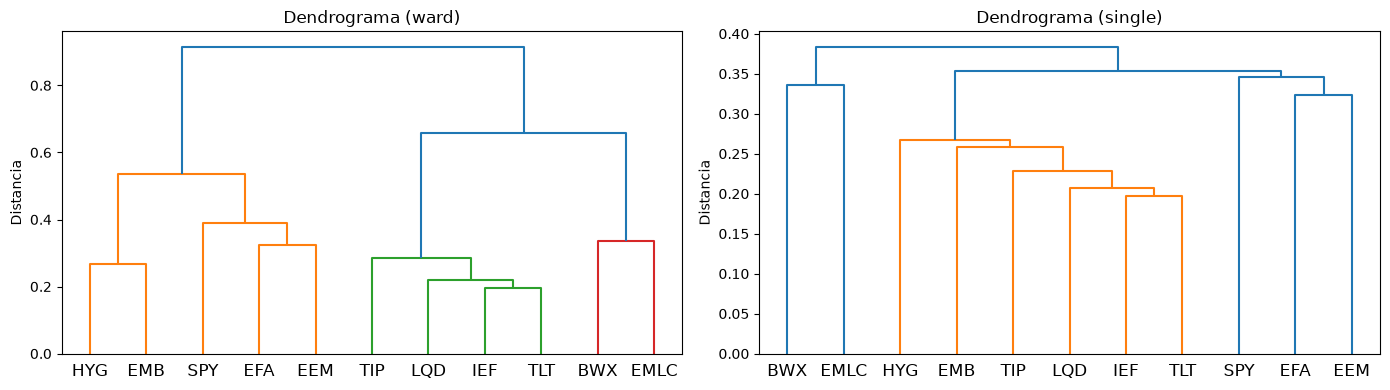

In [12]:
from scipy.cluster.hierarchy import dendrogram
from quantmgmt.optimizers.hrp import cluster

# Árbol con ward, nuestra elección, y con single, el método original de López de Prado. Misma Σ que en la Parte A
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, metodo in zip(axes, ["ward", "single"]):
    dendrogram(cluster(sigma, metodo), labels=list(sigma.index), ax=ax)
    ax.set(title=f"Dendrograma ({metodo})", ylabel="Distancia")
plt.tight_layout(); plt.show()

Con ward el árbol separa tres bloques con sentido económico. El primero es el del riesgo, que junta la bolsa de EE. UU. (SPY), de los desarrollados fuera de EE. UU. (EFA) y de los emergentes (EEM) con el crédito más arriesgado, los bonos corporativos high yield de EE. UU. (HYG) y la deuda soberana emergente en dólares (EMB). El segundo es el refugio, con el Tesoro de EE. UU. a 7-10 años (IEF) y a más de 20 años (TLT), los bonos corporativos con grado de inversión (LQD) y los bonos ligados a la inflación (TIP). El tercero es la deuda en divisa extranjera, la deuda pública de los desarrollados fuera de EE. UU. (BWX) y la deuda emergente en moneda local (EMLC), que dependen sobre todo del tipo de cambio frente al dólar.

Con single, los bonos se agrupan uno detrás de otro en una sola cadena que acaba metiendo a HYG entre los activos refugio, aunque su correlación con SPY es de 0,75.

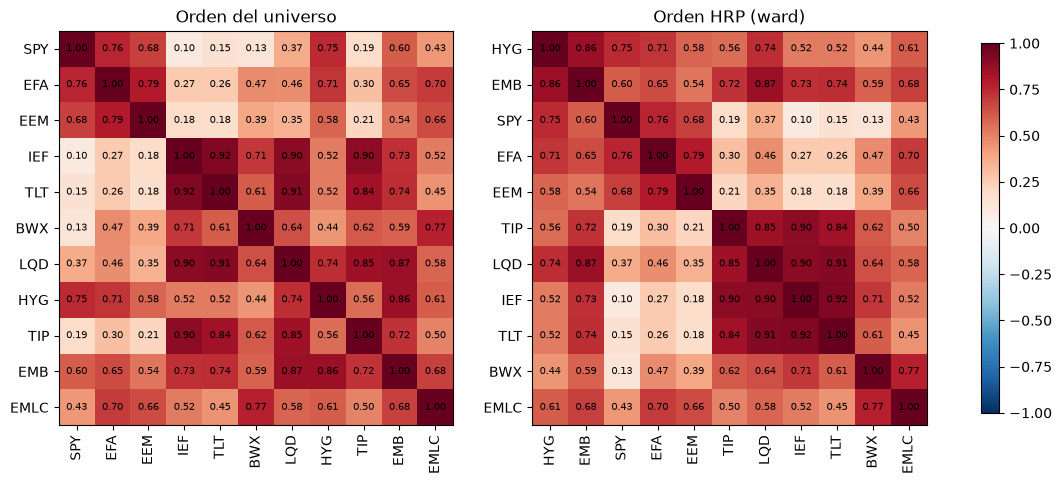

In [13]:
from quantmgmt.optimizers.hrp import quasi_diagonal

# Correlaciones de la ventana en el orden del universo y en el orden de las hojas del árbol (ward)
orden = quasi_diagonal(cluster(sigma, "ward"), list(sigma.index))
vol = np.sqrt(np.diag(sigma))
corr_v = sigma / np.outer(vol, vol)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (titulo, m) in zip(axes, [("Orden del universo", corr_v), ("Orden HRP (ward)", corr_v.loc[orden, orden])]):
    im = ax.imshow(m, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(m)), m.columns, rotation=90)
    ax.set_yticks(range(len(m)), m.index)
    for i in range(len(m)):
        for j in range(len(m)):
            ax.text(j, i, f"{m.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
    ax.set_title(titulo)
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

Las dos matrices tienen los mismos números y solo cambia el orden de los activos. A la derecha los ordenamos como las hojas del árbol, así que los activos parecidos quedan juntos y sus correlaciones altas forman cuadrados rojos alrededor de la diagonal, uno por grupo. La bolsa tiene correlaciones de 0,68 a 0,79 y el refugio, con TIP, LQD, IEF y TLT, de 0,84 a 0,92. HYG y EMB hacen de puente entre los dos bloques, porque se parecen tanto a la bolsa (0,75 entre HYG y SPY) como a los bonos con grado de inversión (0,87 entre EMB y LQD).

En esta ventana no hay ninguna correlación negativa. Entre la bolsa de EE. UU. y el Tesoro va de 0,10 a 0,15, cuando en toda la muestra era negativa, así que estos años los bonos han diversificado menos de lo habitual.

In [14]:
from quantmgmt.optimizers.hrp import hrp_weights, inverse_volatility

w_hrp = hrp_weights(sigma, method="ward")

carteras = pd.DataFrame({
    "HRP (ward)": w_hrp,
    "HRP (single)": hrp_weights(sigma, method="single"),
    "Inversa de la volatilidad": inverse_volatility(sigma),
    "w_mkt": w_mkt,
    "BL": w_bl,
})

# Dos filas de resumen: peso en bolsa y volatilidad de cada cartera con la Σ de la ventana
resumen = pd.DataFrame({
    "Renta variable": carteras.loc[["SPY", "EFA", "EEM"]].sum(),
    "Volatilidad": carteras.apply(lambda w: np.sqrt(w @ sigma @ w)),
}).T
(pd.concat([carteras, resumen]) * 100).round(1)

,HRP (ward),HRP (single),Inversa de la volatilidad,w_mkt,BL
SPY,2.7,3.2,4.8,18.3,34.5
EFA,1.5,1.8,4.8,16.4,0.0
EEM,0.9,1.1,3.7,5.1,9.3
IEF,7.0,9.9,11.6,8.9,0.0
TLT,4.5,2.2,5.5,1.5,1.0
BWX,6.2,8.2,8.6,22.0,18.8
LQD,5.6,13.6,10.4,20.3,17.0
HYG,25.3,24.3,14.6,1.8,0.0
TIP,25.9,17.9,16.1,2.5,19.1
EMB,12.3,7.2,10.2,1.5,0.1


Las cinco carteras se dividen en dos familias. w_mkt y BL parten del tamaño de cada mercado, tienen un 40-44 % en bolsa y una volatilidad del 8,3-8,4 %, dentro del mandato. En w_mkt los mayores pesos son la deuda pública internacional (BWX, 22 %) y los bonos con grado de inversión (LQD, 20 %), que son los mercados más grandes. BL parte de ahí y lo mueve según las visiones, con un 34,5 % en SPY, un 19 % en TIP y nada en EFA, IEF ni HYG.

HRP y la inversa de la volatilidad no miran el tamaño de los mercados ni las rentabilidades, solo el riesgo. Por eso dejan la bolsa en un 5 % y un 13 % y la volatilidad en un 5,5 % y un 6,3 %, por debajo del mandato. La inversa de la volatilidad reparte de forma bastante pareja, entre un 4 % y un 16 % por activo. HRP es mucho más extremo y pone un 63 % en solo tres activos, TIP, HYG y EMB. Primero reparte entre grupos, y dentro del bloque del riesgo HYG y EMB se llevan casi el 90 % porque son casi tres veces menos volátiles que la bolsa.

El caso más llamativo es HYG, que pasa del 1,8 % en w_mkt al 25 % en HRP. El crédito ha estado tranquilo estos tres años y su volatilidad ha sido de solo un 5 %, así que HRP lo trata como un bono seguro aunque su correlación con SPY es de 0,75. Con single la bolsa y la volatilidad apenas cambian, pero el reparto entre bonos sí, porque el árbol corta la lista por otro sitio. LQD sube del 5,6 % al 13,6 % y TIP baja del 26 % al 18 %.

### Contribución al riesgo

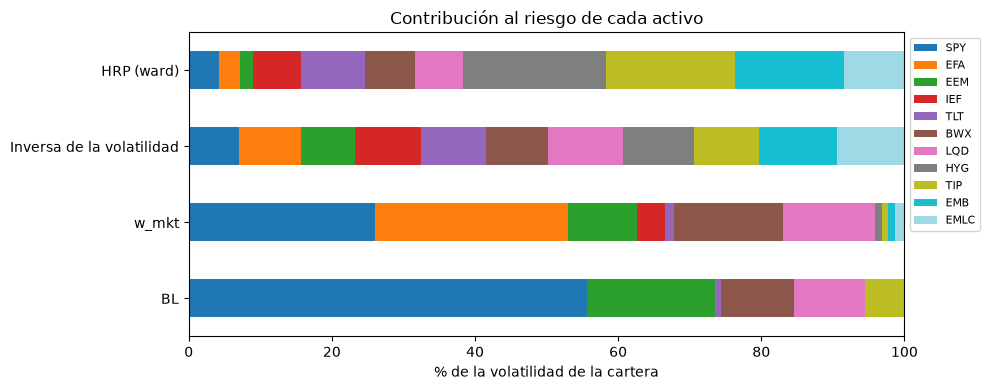

,HRP (ward),Inversa de la volatilidad,w_mkt,BL
SPY,4.2,7.0,26.0,55.7
EFA,2.9,8.7,27.0,0.0
EEM,1.8,7.6,9.6,17.8
IEF,6.8,9.2,3.9,0.0
TLT,8.9,9.0,1.4,0.8
BWX,7.0,8.7,15.1,10.2
LQD,6.8,10.5,12.9,9.8
HYG,20.0,9.9,0.9,0.0
TIP,18.0,9.1,0.8,5.5
EMB,15.3,10.9,1.1,0.1


In [15]:
from quantmgmt.optimizers.hrp import risk_contribution

# Parte de la volatilidad de cada cartera que aporta cada activo, en % del total
rc = pd.DataFrame({
    nombre: risk_contribution(carteras[nombre], sigma) / np.sqrt(carteras[nombre] @ sigma @ carteras[nombre])
    for nombre in ["HRP (ward)", "Inversa de la volatilidad", "w_mkt", "BL"]
}) * 100

fig, ax = plt.subplots(figsize=(10, 4))
rc.T.plot(kind="barh", stacked=True, ax=ax, colormap="tab20")
ax.set(xlabel="% de la volatilidad de la cartera", title="Contribución al riesgo de cada activo")
ax.invert_yaxis()
ax.legend(bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout(); plt.show()

rc.loc["Renta variable"] = rc.loc[["SPY", "EFA", "EEM"]].sum()
rc.round(1)

Las contribuciones al riesgo cuentan algo que no se ve en los pesos. En w_mkt la bolsa es el 40 % del dinero y aporta el 63 % del riesgo, y en BL pesa un 44 % y aporta el 74 %, más de la mitad solo con SPY.

Lo curioso es que la cartera que más equitativamente reparte el riesgo no es HRP, sino la inversa de la volatilidad, donde cada activo aporta entre un 7 % y un 11 %. Al pesar por la inversa de la volatilidad, cada activo pone la misma volatilidad en la cartera y como su correlación con el conjunto es parecida, acaban aportando un riesgo parecido. HRP no busca igualar a los activos sino a los grupos, y concentra más de la mitad del riesgo en HYG, TIP y EMB.

# Parte C. Comparación

En las partes A y B hemos construido las carteras con una sola ventana, la de octubre de 2023 a septiembre de 2026, y las hemos comparado por sus pesos y por su riesgo. Falta saber cómo se habrían comportado. Para eso repetimos la construcción de cada cartera cada trimestre desde 2013, solo con la información que había en ese momento, y medimos lo que pasó en el trimestre siguiente.

## 7. Backtest fuera de muestra

El backtest está en `quantmgmt/backtest/engine.py`. En cada rebalanceo, la función que construye la cartera recibe solo los retornos diarios de los tres años anteriores, así que nunca ve el futuro. Rebalanceamos el último día de cada trimestre, como dice el mandato, y entre dos rebalanceos no tocamos la cartera, de modo que los pesos se mueven con los precios. El primer trimestre con tres años completos de datos detrás termina el 30 de septiembre de 2013, y el periodo fuera de muestra va de octubre de 2013 a septiembre de 2026, trece años con 52 rebalanceos. El 30 de septiembre de 2026 ya no tiene retornos detrás. Ese rebalanceo usaría la misma ventana que las partes A y B, y daría las mismas carteras de Black-Litterman y HRP que ya hemos analizado.

Cada cartera se construye igual que en el resto del notebook. La equiponderada pone un 1/11 en cada ETF. La de mínima varianza y la de máximo Sharpe salen del módulo de la Práctica 2, solo con posiciones largas y sin topes por activo. Para el máximo Sharpe usamos la media histórica de la ventana y, como tipo sin riesgo, la media del RF de Ken French en esos tres años, igual que en la Práctica 2. Black-Litterman repite la Parte A en cada rebalanceo. Los pesos de mercado son siempre los de Doeswijk de cierre de 2012, pero Σ, δ y Π se vuelven a estimar con cada ventana, y las tres visiones y sus confianzas se mantienen. HRP usa ward, como en la Parte B.

Añadimos una sexta columna con el benchmark del mandato, w_mkt rebalanceada cada trimestre. No es una de las cinco carteras del enunciado, pero sin ella no podríamos saber si alguna cumple el objetivo de batirlo en un 2-3 % anual. Además es lo que daría Black-Litterman sin visiones, porque en el apartado 3 vimos que el máximo Sharpe con Π es la propia cartera de mercado.

Medimos cada cartera con las métricas de la Práctica 1, con el tipo sin riesgo medio del periodo para el Sharpe y el Sortino y con el benchmark para el tracking error. Añadimos tres medidas más. En cada rebalanceo, la rotación es la mitad de la suma de los cambios de peso, que es la parte de la cartera que hay que vender para comprar otra cosa. La rotación media anual suma la de todos los rebalanceos y la divide entre los trece años, así que un 100 % equivale a cambiar la cartera entera una vez al año. El primer rebalanceo no cuenta, porque parte de liquidez. El número efectivo de activos es 1 / Σw², que vale 11 en la equiponderada y 1 si todo está en un solo activo. En la tabla damos su media en los 52 rebalanceos, igual que el peso medio en bolsa, que ayuda a entender el resto. No restamos costes de transacción. Con ETF tan líquidos son pequeños, y la rotación ya dice qué carteras los pagarían más.

In [16]:
from quantmgmt.backtest.engine import effective_assets, run_backtest
from quantmgmt.data.factors import download_ff_factors
from quantmgmt.optimizers.mean_variance import min_variance

# Tipo sin riesgo mensual de Ken French, el mismo que usamos en la Práctica 2
rf_mes = download_ff_factors(start="2010-01-01", end="2026-09-30")["RF"]

def cartera_max_sharpe(r, max_weight=None):
    # Media y Σ históricas de la ventana, con el tipo sin riesgo medio de esos tres años
    mu, s = estimate_inputs(r, periods_per_year=252)
    return max_sharpe(mu, s, rf=rf_mes.loc[r.index[0]:r.index[-1]].mean() * 12, max_weight=max_weight)

def cartera_bl(r, P_=P, Q_=Q, conf_=confianza):
    # Como en la Parte A, con la Σ de cada ventana. w_mkt, las visiones y las confianzas no cambian
    _, s = estimate_inputs(r, periods_per_year=252)
    pi_t = implied_returns(w_mkt, s, risk_aversion(w_mkt, s, SHARPE_MKT))
    var_ = np.diag(P_ @ (tau * s) @ P_.T)
    om = pd.DataFrame(np.diag(var_ * (1 - conf_) / conf_), index=P_.index, columns=P_.index)
    mu, sig = posterior(pi_t, s, P_, Q_, om, tau)
    return max_sharpe(mu, sig)

ESTRATEGIAS = {
    "Equiponderada": lambda r: pd.Series(1 / r.shape[1], index=r.columns),
    "Mín. varianza": lambda r: min_variance(estimate_inputs(r, periods_per_year=252)[1]),
    "Máx. Sharpe": cartera_max_sharpe,
    "BL": cartera_bl,
    "HRP": lambda r: hrp_weights(estimate_inputs(r, periods_per_year=252)[1], method="ward"),
    "Benchmark": lambda r: w_mkt,
}

# Rebalanceo trimestral con los tres años anteriores. Cada backtest devuelve retornos, pesos y rotación
bt = {nombre: run_backtest(rent, estrategia, years=3, freq="QE") for nombre, estrategia in ESTRATEGIAS.items()}
retornos_bt = pd.DataFrame({nombre: r for nombre, (r, _, _) in bt.items()})

print(f"Fuera de muestra: {retornos_bt.index[0].date()} a {retornos_bt.index[-1].date()} "
      f"({len(retornos_bt)} días y {len(bt['BL'][1])} rebalanceos)")

Fuera de muestra: 2013-10-01 a 2026-09-30 (3269 días y 52 rebalanceos)


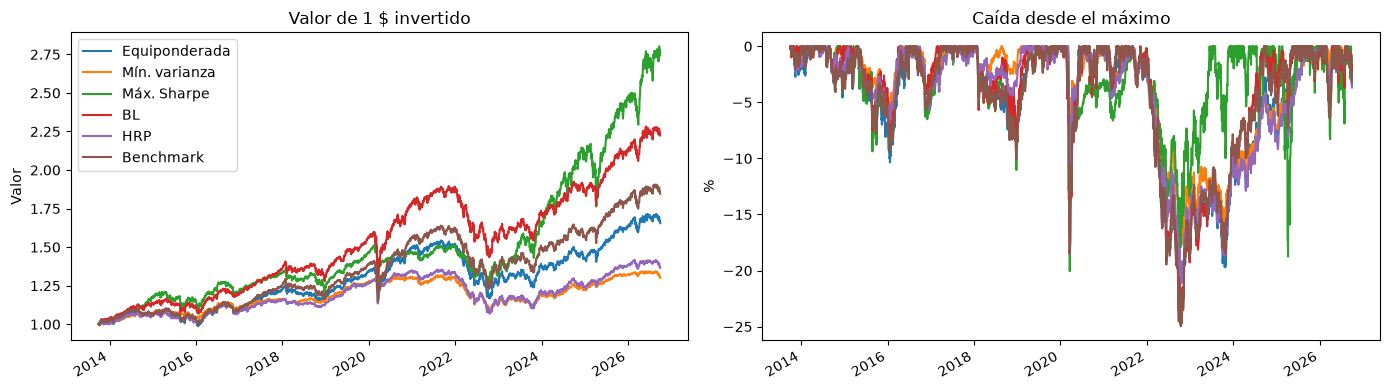

In [17]:
from quantmgmt.risk import drawdown_series

# Valor de 1 $ invertido en octubre de 2013 y caída desde el máximo anterior
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
(1 + retornos_bt).cumprod().plot(ax=axes[0], title="Valor de 1 $ invertido", xlabel="", ylabel="Valor")
(-drawdown_series(retornos_bt) * 100).plot(ax=axes[1], title="Caída desde el máximo", xlabel="", ylabel="%", legend=False)
plt.tight_layout(); plt.show()

In [18]:
from quantmgmt.risk import risk_summary

# Tipo sin riesgo diario medio del periodo fuera de muestra, para el Sharpe y el Sortino
rf_dia = rf_mes.loc[retornos_bt.index[0]:].mean() * 12 / 252

def metricas_bt(resultados):
    # Métricas de la Práctica 1 más rotación media anual, número efectivo de activos y peso medio en bolsa
    r = pd.DataFrame({n: ret for n, (ret, _, _) in resultados.items()})
    duracion = len(r) / 252   # años fuera de muestra
    tabla = risk_summary(r, benchmark=retornos_bt["Benchmark"], periods_per_year=252, risk_free_rate=rf_dia)
    tabla["Rotación media anual"] = pd.Series({n: rot.sum() / duracion for n, (_, _, rot) in resultados.items()})
    tabla["Nº efectivo de activos"] = pd.Series({n: effective_assets(w).mean() for n, (_, w, _) in resultados.items()})
    tabla["Peso medio en bolsa"] = pd.Series({n: w[["SPY", "EFA", "EEM"]].sum(axis=1).mean() for n, (_, w, _) in resultados.items()})
    return tabla

print(f"Tipo sin riesgo medio: {rf_dia * 252:.2%}")
metricas_bt(bt).T.round(3)

Tipo sin riesgo medio: 1.80%


,Equiponderada,Mín. varianza,Máx. Sharpe,BL,HRP,Benchmark
Rentabilidad anualizada,0.042,0.022,0.083,0.065,0.026,0.051
CAGR,0.040,0.021,0.081,0.064,0.024,0.048
Volatilidad anualizada,0.077,0.050,0.107,0.087,0.058,0.084
Desviación a la baja,0.056,0.036,0.073,0.062,0.042,0.061
Máx. drawdown,0.244,0.177,0.200,0.243,0.211,0.250
Tiempo bajo el agua,957.000,1030.000,835.000,717.000,1026.000,767.000
Tiempo de recuperación,673.000,724.000,816.000,484.000,720.000,487.000
Sharpe,0.310,0.070,0.613,0.546,0.133,0.390
Sortino,0.427,0.097,0.892,0.760,0.183,0.541
Calmar,0.163,0.116,0.404,0.262,0.115,0.194


In [19]:
# Rentabilidad de cada año natural, en %. 2013 va de octubre a diciembre y 2026 de enero a septiembre
anual = (1 + retornos_bt).groupby(retornos_bt.index.year).prod() - 1
(anual * 100).round(1)

,Equiponderada,Mín. varianza,Máx. Sharpe,BL,HRP,Benchmark
Date,,,,,,
2013,1.5,0.2,2.5,4.2,0.3,3.2
2014,4.5,6.7,14.4,8.7,5.1,3.5
2015,-4.0,-1.9,-1.7,-1.8,-3.1,-2.6
2016,6.5,5.8,5.2,7.3,5.8,5.3
2017,13.0,4.9,10.1,13.9,7.3,14.3
2018,-4.9,-1.0,-7.3,-3.3,-2.4,-5.0
2019,15.0,10.4,18.2,18.7,11.8,16.7
2020,12.0,2.9,0.4,14.7,6.7,12.6
2021,1.2,-0.3,2.6,5.5,-1.0,3.8


Black-Litterman y máximo Sharpe son las únicas carteras que baten al benchmark. Black-Litterman ha rendido un 6,4 % anual frente al 4,8 % del benchmark, con una volatilidad muy parecida, un 8,7 % frente a un 8,4 %, y una caída máxima algo menor, del 24 % frente al 25 %. Su Sharpe es de 0,55 frente a 0,39. Se aparta poco del benchmark, con un tracking error del 1,8 %, y rota un 13 % al año. Lo hace con una media del 35 % en SPY, casi el doble que el mercado, y sin nada en EFA, justo lo que dicen las visiones.

Máximo Sharpe es la que más ha rendido, un 8,1 % anual con un Sharpe de 0,61, pero es una cartera muy distinta. Tiene de media solo 2,1 activos efectivos y en los nueve rebalanceos que van de marzo de 2023 a marzo de 2025 lo puso todo en SPY. Rota un 84 % al año, seis veces más que Black-Litterman, y su volatilidad, un 10,7 %, se sale del 8-10 % del mandato. Gana porque SPY ha sido de lejos el mejor activo del periodo, con un 14,3 % anual, y la media histórica de cada ventana lo señalaba. Es el mismo método que en la Práctica 2 quedó por detrás de la equiponderada y de SPY fuera de muestra, así que su resultado depende de que el activo que mejor lo ha hecho lo siga haciendo. Su caída máxima, del 20 %, no fue en 2022 sino en marzo de 2020. Entonces tenía dos tercios de la cartera en bonos corporativos (LQD), que cayeron con fuerza en la crisis de liquidez de la pandemia.

HRP y la mínima varianza son las carteras más tranquilas, con un 5,8 % y un 5,0 % de volatilidad, pero también las que menos han rendido, un 2,4 % y un 2,1 % anual, muy poco por encima del 1,8 % del tipo sin riesgo. Casi todo su dinero está en bonos, con un 6 % y un 3,5 % de media en bolsa, y los bonos han rendido poco en estos trece años. TIP e IEF, sus dos mayores posiciones, han ganado un 2,0 % y un 1,2 % anual, casi lo mismo que la liquidez. Su volatilidad se queda además por debajo del mandato, así que no aprovechan el riesgo que el cliente está dispuesto a asumir. Tampoco se libran de las caídas. En 2022 la bolsa y los bonos cayeron a la vez, y su caída máxima llegó al 21 % y al 18 %, no tan lejos del 25 % del benchmark aunque su volatilidad es entre un 30 % y un 40 % menor.

La equiponderada queda por detrás del benchmark, un 4,0 % frente a un 4,8 %, con algo menos de riesgo. Pone un 27 % en bolsa, frente al 40 % del benchmark, y la mitad de peso en SPY, que ha sido el mejor activo del periodo.

En la tabla por años se ve que 2022 fue el peor año para todas, con pérdidas de entre el 12 % y el 18 %. Black-Litterman perdió algo más que el benchmark ese año, un 18,3 % frente a un 17,3 %, pero lo recuperó en 2023 y 2024.

In [20]:
# Qué habría pasado con otras decisiones. Primero, lo que han hecho de verdad los diferenciales de las visiones
realizado = P @ (rent.loc[retornos_bt.index].mean() * 252)
print(pd.DataFrame({"Q": Q, "Realizado (oct. 2013 - sep. 2026)": realizado}).round(4))

conf_alta = pd.Series([0.45, 0.50, 0.70], index=P.index)
ALTERNATIVAS = {
    "BL sin V1": lambda r: cartera_bl(r, P.loc[["V2", "V3"]], Q[["V2", "V3"]], confianza[["V2", "V3"]]),
    "BL solo con V1": lambda r: cartera_bl(r, P.loc[["V1"]], Q[["V1"]], confianza[["V1"]]),
    "BL con confianzas 45/50/70": lambda r: cartera_bl(r, conf_=conf_alta),
    "Máx. Sharpe con tope del 30 %": lambda r: cartera_max_sharpe(r, max_weight=0.30),
    "HRP (single)": lambda r: hrp_weights(estimate_inputs(r, periods_per_year=252)[1], method="single"),
    "Inversa de la volatilidad": lambda r: inverse_volatility(estimate_inputs(r, periods_per_year=252)[1]),
}
bt_alt = {nombre: run_backtest(rent, estrategia, years=3, freq="QE") for nombre, estrategia in ALTERNATIVAS.items()}

orden_alt = ["BL", "BL sin V1", "BL solo con V1", "BL con confianzas 45/50/70", "Máx. Sharpe",
             "Máx. Sharpe con tope del 30 %", "HRP", "HRP (single)", "Inversa de la volatilidad", "Benchmark"]
columnas = ["CAGR", "Volatilidad anualizada", "Sharpe", "Máx. drawdown", "Tracking error",
            "Rotación media anual", "Nº efectivo de activos", "Peso medio en bolsa"]
todos = bt | bt_alt
metricas_bt({n: todos[n] for n in orden_alt})[columnas].round(3)

       Q  Realizado (oct. 2013 - sep. 2026)
V1  0.04                             0.0667
V2  0.02                            -0.0670
V3  0.01                             0.0074


,CAGR,Volatilidad anualizada,Sharpe,Máx. drawdown,Tracking error,Rotación media anual,Nº efectivo de activos,Peso medio en bolsa
BL,0.064,0.087,0.546,0.243,0.018,0.132,4.740,0.436
BL sin V1,0.045,0.085,0.349,0.260,0.009,0.084,6.319,0.398
BL solo con V1,0.068,0.086,0.604,0.236,0.022,0.114,3.869,0.432
BL con confianzas 45/50/70,0.082,0.100,0.664,0.222,0.042,0.149,2.680,0.539
Máx. Sharpe,0.081,0.107,0.613,0.200,0.068,0.835,2.078,0.526
Máx. Sharpe con tope del 30 %,0.066,0.081,0.606,0.193,0.042,0.579,3.841,0.373
HRP,0.024,0.058,0.133,0.211,0.051,0.194,6.885,0.060
HRP (single),0.025,0.060,0.139,0.211,0.047,0.226,6.803,0.065
Inversa de la volatilidad,0.031,0.064,0.221,0.228,0.036,0.066,9.431,0.144
Benchmark,0.048,0.084,0.390,0.250,0.000,0.057,6.174,0.398


Las visiones son la parte más delicada del backtest. Las hemos formulado hoy y las aplicamos desde 2013, así que si alguna resume lo que ya ha pasado, el backtest le da a Black-Litterman una ventaja que no habría tenido en su momento. Es lo que pasa con la primera. Entre octubre de 2013 y septiembre de 2026, SPY batió a EFA en un 6,7 % anual, más que el 4 % que pedimos. La segunda fue justo al revés. EEM quedó un 6,7 % por detrás de SPY cuando esperábamos que lo batiera en un 2 %. La tercera salió parecida a lo previsto, con TIP por delante de IEF en un 0,7 %.

Sin la primera visión, Black-Litterman rinde un 4,5 % anual, por debajo del 4,8 % del benchmark, y con solo la primera rinde un 6,8 %. Toda su ventaja viene de la visión que mejor conocíamos al formularla. Con las confianzas que pusimos al principio, del 45 %, 50 % y 70 %, habría rendido todavía más, un 8,2 % con un Sharpe de 0,66, pero con 2,7 activos efectivos, un 54 % en bolsa y un tracking error del 4,2 %, más del doble que con las confianzas que hemos elegido.

Al máximo Sharpe le basta un tope del 30 % por activo para parecerse a una cartera razonable. Rinde un 6,6 % con un 8,1 % de volatilidad, dentro del mandato, sube a 3,8 activos efectivos y su caída máxima baja al 19 %, aunque sigue rotando un 58 % al año. HRP con single da casi lo mismo que con ward. La inversa de la volatilidad, con un 14 % en bolsa, rinde algo más que HRP, un 3,1 % anual, y es la cartera más diversificada después de la equiponderada, con 9,4 activos efectivos.

## Conclusión

Ante un comité de inversiones defenderíamos Black-Litterman. Es la única de las cinco carteras que bate al benchmark sin salirse del mandato. Ha rendido un 1,5 % anual más que el benchmark, con una volatilidad del 8,7 %, dentro del 8-10 % que pedimos, y una caída máxima del 24 %, por debajo del 30 % que aceptamos. Se aparta poco del benchmark, con un tracking error del 1,8 %, rota poco y cada diferencia con el mercado se explica con una visión concreta. Máximo Sharpe ha rendido más, pero con una cartera que llegó a estar entera en SPY, que cambia casi por completo cada año y cuya volatilidad se sale del mandato. HRP y la mínima varianza tienen poco riesgo, pero se quedan por debajo de la volatilidad que pide el mandato y rinden poco más que la liquidez.

Aun así no llegamos al objetivo del mandato. Pedíamos batir al benchmark en un 2-3 % anual y Black-Litterman lo ha batido en un 1,5 %. Máximo Sharpe lo supera, pero a costa de salirse del límite de volatilidad.

El miembro más escéptico del comité diría que la ventaja de Black-Litterman no viene del modelo sino de nosotros. La primera visión, que EE. UU. batirá al resto de desarrollados, la hemos formulado en 2026 sabiendo que lleva más de una década haciéndolo, y sin ella Black-Litterman rinde menos que el benchmark. La segunda, la única que iba en contra de lo que ha pasado, ha restado. El backtest premia la visión que ya conocíamos y castiga la que de verdad era una apuesta. Además, trece años en los que una sola bolsa ha dominado tanto son una muestra muy particular, y nada asegura que la visión que ha funcionado lo siga haciendo.

Tiene razón en que el backtest no demuestra que sepamos acertar con las visiones. Lo que sí muestra es que Black-Litterman limita lo que cuesta equivocarse. La segunda visión falló por casi 9 puntos al año, y aun así la cartera sin la primera visión solo quedó 0,3 puntos por detrás del benchmark, con un tracking error del 0,9 % y una rotación del 8 % al año. Por eso le pediríamos al comité que juzgue la cartera por cómo controla el riesgo de las visiones y no por el 1,5 % de este backtest, y que las visiones se revisen al menos una vez al año.